# NACC Phase 1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

UDS = pd.read_csv('udslong_imputed.csv')
MRI = pd.read_csv('mriscanclean.csv')

## Task 1

In [3]:
UDS.shape, MRI.shape


((1237, 180), (1237, 126))

## Task 2

In [4]:
UDS['NACCID'].nunique(), UDS['NACCID'].duplicated().sum()


(1237, np.int64(0))

In [5]:
MRI['NACCID'].nunique(), MRI['NACCID'].duplicated().sum()


(1237, np.int64(0))

In [6]:
UDS.columns


Index(['NACCID', 'SEX', 'HISPANIC', 'HISPOR', 'RACE', 'PRIMLANG', 'EDUC',
       'MARISTAT', 'NACCLIVS', 'INDEPEND',
       ...
       'NACCAPOE', 'NACCUDSD', 'MEMORY', 'ORIENT', 'JUDGMENT', 'COMMUN',
       'HOMEHOBB', 'PERSCARE', 'CDRSUM', 'CDRGLOB'],
      dtype='str', length=180)

In [7]:
MRI.columns


Index(['NACCID', 'LH_CAUDALANTERIORCINGULATE_GVOL',
       'RH_CAUDALANTERIORCINGULATE_GVOL', 'LH_CAUDALANTERIORCINGULATE_AVGTH',
       'RH_CAUDALANTERIORCINGULATE_AVGTH', 'LH_CAUDALMIDDLEFRONTAL_GVOL',
       'RH_CAUDALMIDDLEFRONTAL_GVOL', 'LH_CAUDALMIDDLEFRONTAL_AVGTH',
       'RH_CAUDALMIDDLEFRONTAL_AVGTH', 'LH_CUNEUS_GVOL',
       ...
       'RH_SUPRAMARGINAL_AVGTH', 'LH_TRANSVERSETEMPORAL_GVOL',
       'RH_TRANSVERSETEMPORAL_GVOL', 'LH_TRANSVERSETEMPORAL_AVGTH',
       'RH_TRANSVERSETEMPORAL_AVGTH', 'LH_INSULA_GVOL', 'RH_INSULA_GVOL',
       'LH_INSULA_AVGTH', 'RH_INSULA_AVGTH', 'NACCUDSD'],
      dtype='str', length=126)

## Task 3

In [8]:
UDS['NACCID'].isnull().sum(), MRI['NACCID'].isnull().sum()


(np.int64(0), np.int64(0))

In [9]:
UDS['NACCID'].duplicated().sum(), MRI['NACCID'].duplicated().sum()


(np.int64(0), np.int64(0))

## Task 4

In [10]:
UDS.dtypes


NACCID          str
SEX         float64
HISPANIC    float64
HISPOR      float64
RACE        float64
             ...   
COMMUN      float64
HOMEHOBB    float64
PERSCARE    float64
CDRSUM      float64
CDRGLOB     float64
Length: 180, dtype: object

In [11]:
MRI.dtypes


NACCID                                  str
LH_CAUDALANTERIORCINGULATE_GVOL       int64
RH_CAUDALANTERIORCINGULATE_GVOL       int64
LH_CAUDALANTERIORCINGULATE_AVGTH    float64
RH_CAUDALANTERIORCINGULATE_AVGTH    float64
                                     ...   
LH_INSULA_GVOL                        int64
RH_INSULA_GVOL                        int64
LH_INSULA_AVGTH                     float64
RH_INSULA_AVGTH                     float64
NACCUDSD                              int64
Length: 126, dtype: object

In [12]:
UDS.nunique().sort_values()


NACCOMS        1
SEX            2
NACCFMS        2
NACCFADM       2
NACCFFTD       2
            ... 
HEIGHT       170
WEIGHT       179
TRAILB       218
NACCBMI      239
NACCID      1237
Length: 180, dtype: int64

## Task 5

In [13]:
UDS.isnull().sum().sort_values(ascending=False)


NACCID      0
SEX         0
HISPANIC    0
HISPOR      0
RACE        0
           ..
COMMUN      0
HOMEHOBB    0
PERSCARE    0
CDRSUM      0
CDRGLOB     0
Length: 180, dtype: int64

In [14]:
MRI.isnull().sum().sort_values(ascending=False)


NACCID                              0
LH_CAUDALANTERIORCINGULATE_GVOL     0
RH_CAUDALANTERIORCINGULATE_GVOL     0
LH_CAUDALANTERIORCINGULATE_AVGTH    0
RH_CAUDALANTERIORCINGULATE_AVGTH    0
                                   ..
LH_INSULA_GVOL                      0
RH_INSULA_GVOL                      0
LH_INSULA_AVGTH                     0
RH_INSULA_AVGTH                     0
NACCUDSD                            0
Length: 126, dtype: int64

In [15]:
UDS.isnull().mean().sort_values(ascending=False) * 100


NACCID      0.0
SEX         0.0
HISPANIC    0.0
HISPOR      0.0
RACE        0.0
           ... 
COMMUN      0.0
HOMEHOBB    0.0
PERSCARE    0.0
CDRSUM      0.0
CDRGLOB     0.0
Length: 180, dtype: float64

In [16]:
MRI.isnull().mean().sort_values(ascending=False) * 100


NACCID                              0.0
LH_CAUDALANTERIORCINGULATE_GVOL     0.0
RH_CAUDALANTERIORCINGULATE_GVOL     0.0
LH_CAUDALANTERIORCINGULATE_AVGTH    0.0
RH_CAUDALANTERIORCINGULATE_AVGTH    0.0
                                   ... 
LH_INSULA_GVOL                      0.0
RH_INSULA_GVOL                      0.0
LH_INSULA_AVGTH                     0.0
RH_INSULA_AVGTH                     0.0
NACCUDSD                            0.0
Length: 126, dtype: float64

In [17]:
UDS.duplicated().sum(), MRI.duplicated().sum()


(np.int64(0), np.int64(0))

In [18]:
special_values = {
    'HISPANIC': [9, -4],
    'RACE': [99, -4],
    'EDUC': [8, 9, 99, -4],
    'NACCAPOE': [9, -4],
    'MOCATOTS': [88, 99, -4],
    'HYPERTEN': [-4, 8, 9, 99],
    'TRAILA': [995, 996, 997, 998, -4],
    'TRAILB': [995, 996, 997, 998, -4]
}

for col, values in special_values.items():
    if col in UDS.columns:
        print(col)
        print(UDS[col][UDS[col].isin(values)].value_counts())

HISPANIC
HISPANIC
9.0    9
Name: count, dtype: int64
RACE
RACE
99.0    3
Name: count, dtype: int64
EDUC
EDUC
99.0    2
8.0     2
9.0     2
Name: count, dtype: int64
NACCAPOE
NACCAPOE
9.0    278
Name: count, dtype: int64
MOCATOTS
MOCATOTS
88.0    4
Name: count, dtype: int64
HYPERTEN
HYPERTEN
9.0    11
Name: count, dtype: int64
TRAILA
TRAILA
996.0    9
997.0    8
998.0    2
995.0    2
Name: count, dtype: int64
TRAILB
TRAILB
996.0    38
997.0     8
998.0     7
995.0     2
Name: count, dtype: int64


In [18]:
for col in UDS.select_dtypes(include=np.number).columns:
    values = UDS[col].dropna()
    if len(values) > 0 and (values % 1 != 0).any():
        print(col, (values % 1 != 0).sum())

NACCFAM 3
NACCMOM 5
NACCDAD 1
NACCAM 5
NACCAMS 23
NACCFM 6
NACCOM 6
ANYMEDS 1
TOBAC30 5
TOBAC100 24
SMOKYRS 19
PACKSPER 23
QUITSMOK 18
CVHATT 5
CVAFIB 5
CVANGIO 3
CVBYPASS 1
CVOTHR 4
CBSTROKE 3
CBTIA 2
NACCTBI 19
TBI 164
TBIBRIEF 97
TBIEXTEN 66
TBIWOLOS 87
DIABETES 12
DIABTYPE 12
HYPERTEN 22
HYPERCHO 25
B12DEF 14
THYROID 14
ARTHRIT 247
ARTHTYPE 233
ARTHUPEX 228
ARTHLOEX 216
ARTHSPIN 187
ARTHUNK 17
INCONTU 11
INCONTF 5
APNEA 174
RBD 48
INSOMN 144
OTHSLEEP 48
ALCOHOL 3
PTSD 38
BIPOLAR 7
SCHIZ 7
DEP2YRS 16
DEPOTHR 18
ANXIETY 153
OCD 12
NPSYDEV 41
PSYCDIS 1
NACCAANX 1
NACCAC 2
NACCAHTN 2
NACCAMD 2
NACCANGI 2
NACCCCBS 2
NACCDIUR 2
NACCLIPL 2
NACCNSD 2
NACCPDMD 1
HEIGHT 673
WEIGHT 31
BPSYS 39
BPDIAS 50
HRATE 36
VISION 7
VISCORR 8
VISWCORR 19
HEARING 9
HEARAID 7
HEARWAID 18
NACCBMI 1136
NACCNREX 22
NORMEXAM 162
NPIQINF 62
DEL 15
DELSEV 16
AGIT 51
AGITSEV 47
DEPD 55
DEPDSEV 59
ANX 53
ANXSEV 54
ELAT 16
ELATSEV 16
APA 25
APASEV 25
DISN 24
DISNSEV 25
IRR 56
IRRSEV 51
NITE 25
NITESEV 31
APP 36
APP

## Task 6

In [19]:
for col in ['SEX', 'HISPANIC', 'RACE', 'MARISTAT', 'NACCAPOE', 'NACCUDSD']:
    if col in UDS.columns:
        print(col)
        print(UDS[col].value_counts(dropna=False).sort_index())

SEX
SEX
1.0    497
2.0    740
Name: count, dtype: int64
HISPANIC
HISPANIC
0.0    1151
1.0      77
9.0       9
Name: count, dtype: int64
RACE
RACE
1.0     1019
2.0      160
3.0       15
5.0       26
50.0      14
99.0       3
Name: count, dtype: int64
MARISTAT
MARISTAT
1.0    857
2.0     97
3.0    163
4.0      9
5.0     81
6.0     27
9.0      3
Name: count, dtype: int64
NACCAPOE
NACCAPOE
1.0    493
2.0    290
3.0     83
4.0     73
5.0     17
6.0      3
9.0    278
Name: count, dtype: int64
NACCUDSD
NACCUDSD
1.0    847
2.0      7
3.0    252
4.0    131
Name: count, dtype: int64


In [20]:
for col in UDS.select_dtypes(include=np.number).columns:
    if UDS[col].nunique() <= 20 and col != 'NACCID':
        print(col)
        print(UDS[col].value_counts(dropna=False).sort_index())

SEX
SEX
1.0    497
2.0    740
Name: count, dtype: int64
HISPANIC
HISPANIC
0.0    1151
1.0      77
9.0       9
Name: count, dtype: int64
HISPOR
HISPOR
1.0       31
2.0       15
3.0        2
4.0        9
5.0        8
6.0        8
50.0       3
88.0    1160
99.0       1
Name: count, dtype: int64
RACE
RACE
1.0     1019
2.0      160
3.0       15
5.0       26
50.0      14
99.0       3
Name: count, dtype: int64
PRIMLANG
PRIMLANG
1.0    1185
2.0      39
3.0       1
6.0       1
8.0      10
9.0       1
Name: count, dtype: int64
MARISTAT
MARISTAT
1.0    857
2.0     97
3.0    163
4.0      9
5.0     81
6.0     27
9.0      3
Name: count, dtype: int64
NACCLIVS
NACCLIVS
1.0    254
2.0    827
3.0     82
4.0     70
5.0      1
9.0      3
Name: count, dtype: int64
INDEPEND
INDEPEND
1.0    1123
2.0      84
3.0      26
4.0       2
9.0       2
Name: count, dtype: int64
RESIDENC
RESIDENC
1.0    1211
2.0      18
3.0       6
9.0       2
Name: count, dtype: int64
NACCNIHR
NACCNIHR
1.0     1004
2.0      146
3.0   

## Task 7

In [21]:
cols = ['NACCAGE', 'CDRSUM', 'CDRGLOB', 'MOCATOTS']
UDS[cols].describe().T

,count,mean,std,min,25%,50%,75%,max
NACCAGE,1237.0,68.192401,8.039054,41.0,63.0,68.0,74.0,91.0
CDRSUM,1237.0,0.822150,1.723006,0.0,0.0,0.0,1.0,15.0
CDRGLOB,1237.0,0.211803,0.327425,0.0,0.0,0.0,0.5,2.0
MOCATOTS,1237.0,24.647696,5.753982,0.0,23.0,25.4,27.0,88.0


In [22]:
UDS[cols].quantile([0.25, 0.50, 0.75]).T

,0.25,0.50,0.75
NACCAGE,63.0,68.0,74.0
CDRSUM,0.0,0.0,1.0
CDRGLOB,0.0,0.0,0.5
MOCATOTS,23.0,25.4,27.0


In [23]:
MRI.describe().T

,count,mean,std,min,25%,50%,75%,max
LH_CAUDALANTERIORCINGULATE_GVOL,1237.0,2659.510105,522.837436,16.000,2326.000,2633.000,2985.000,5647.000
RH_CAUDALANTERIORCINGULATE_GVOL,1237.0,2038.590946,477.963125,105.000,1724.000,2024.000,2313.000,5462.000
LH_CAUDALANTERIORCINGULATE_AVGTH,1237.0,2.400001,0.191175,0.738,2.303,2.406,2.508,3.272
RH_CAUDALANTERIORCINGULATE_AVGTH,1237.0,2.267364,0.204870,0.738,2.135,2.256,2.384,3.479
LH_CAUDALMIDDLEFRONTAL_GVOL,1237.0,5964.727567,1181.842284,344.000,5247.000,5936.000,6742.000,9897.000
...,...,...,...,...,...,...,...,...
LH_INSULA_GVOL,1237.0,5725.171382,797.765963,412.000,5293.000,5720.000,6222.000,8028.000
RH_INSULA_GVOL,1237.0,5827.328213,796.259669,270.000,5387.000,5835.000,6295.000,8190.000
LH_INSULA_AVGTH,1237.0,2.876901,0.212314,0.765,2.769,2.885,3.002,3.563
RH_INSULA_AVGTH,1237.0,2.857935,0.199251,1.069,2.749,2.868,2.975,4.353


## Task 8

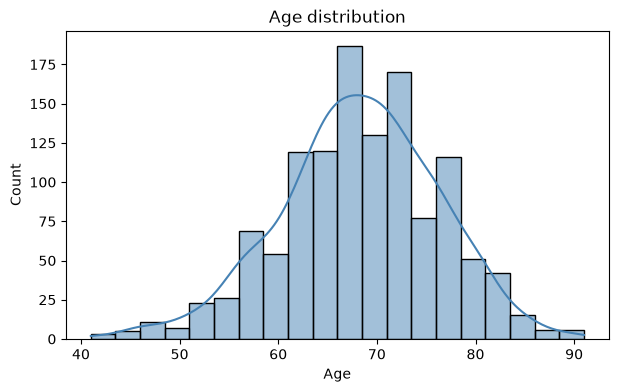

In [57]:
plt.figure(figsize=(7, 4))
sns.histplot(data=UDS, x='NACCAGE', bins=20, color='steelblue' , kde = True)
plt.title('Age distribution')
plt.xlabel('Age')
plt.show()

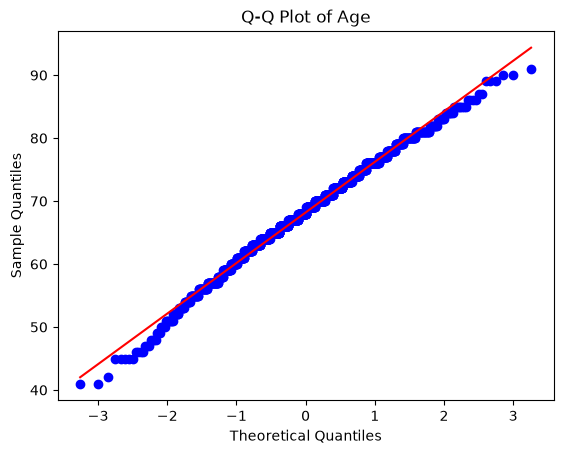

In [61]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(UDS['NACCAGE'].dropna(), dist='norm', plot=plt)
plt.title('Q-Q Plot of Age')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.show()

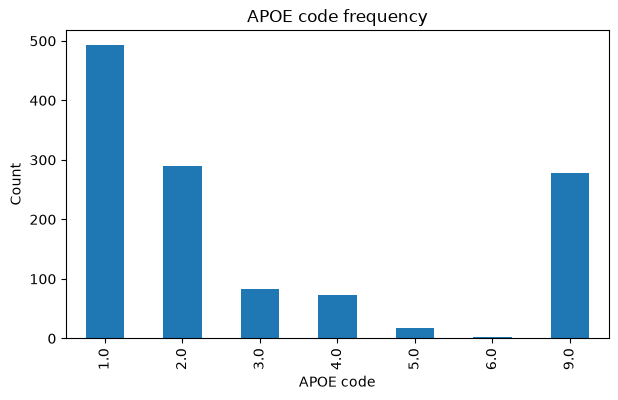

In [21]:
plt.figure(figsize=(7, 4))
UDS['NACCAPOE'].value_counts().sort_index().plot(kind='bar')
plt.title('APOE code frequency')
plt.xlabel('APOE code')
plt.ylabel('Count')
plt.show()

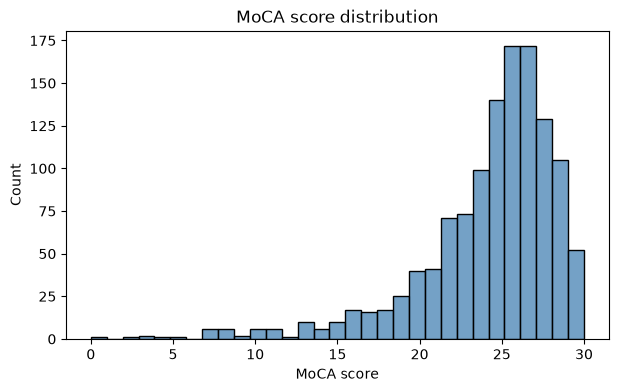

In [ ]:
MOCATOTS_plot = UDS[UDS['MOCATOTS'].between(0, 30)]

plt.figure(figsize=(7, 4))
sns.histplot(data=MOCATOTS_plot, x='MOCATOTS', bins=31, color='steelblue' , kde = True)
plt.title('MoCA score distribution')
plt.xlabel('MoCA score')
plt.show()

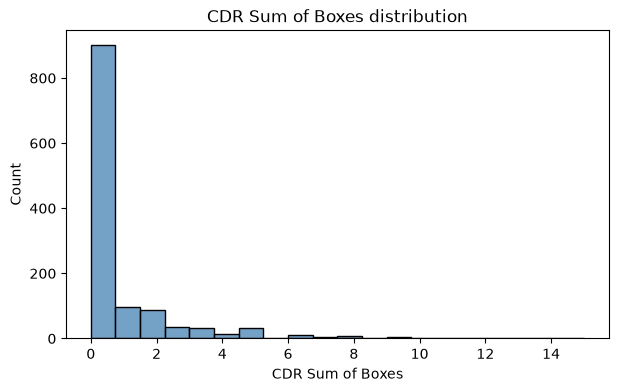

In [23]:
plt.figure(figsize=(7, 4))
sns.histplot(data=UDS, x='CDRSUM', bins=20, color='steelblue')
plt.title('CDR Sum of Boxes distribution')
plt.xlabel('CDR Sum of Boxes')
plt.show()

## Task 9

In [28]:
UDS.groupby('CDRGLOB')['NACCAGE'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
CDRGLOB,,,,
0.0,800,67.156250,67.0,7.959336
0.5,368,70.464674,71.0,7.398641
1.0,60,68.316667,69.0,9.966880
2.0,9,66.555556,66.0,8.110350


In [29]:
UDS.groupby('SEX')['NACCAGE'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
SEX,,,,
1.0,497,68.985915,70.0,7.737230
2.0,740,67.659459,68.0,8.197675


## Task 10

In [30]:
research_question = 'Is APOE genotype associated with cognitive status, and does this association vary with left and right entorhinal cortical thickness?'
print(research_question)

Is APOE genotype associated with cognitive status, and does this association vary with left and right entorhinal cortical thickness?


## Task 11 - Route J1

In [31]:
uds_groups = {
    'Demographic': ['NACCAGE', 'SEX', 'HISPANIC', 'RACE', 'MARISTAT', 'EDUC'],
    'Medical': ['HYPERTEN', 'DIABETES', 'HYPERCHO'],
    'Functional': ['NACCFAM', 'NACCAM', 'NACCFM'],
    'Cognitive': ['MOCATOTS', 'CDRSUM', 'CDRGLOB', 'TRAILA', 'TRAILB']
}

for group, variables in uds_groups.items():
    print(group, [col for col in variables if col in UDS.columns])

Demographic ['NACCAGE', 'SEX', 'HISPANIC', 'RACE', 'MARISTAT', 'EDUC']
Medical ['HYPERTEN', 'DIABETES', 'HYPERCHO']
Functional ['NACCFAM', 'NACCAM', 'NACCFM']
Cognitive ['MOCATOTS', 'CDRSUM', 'CDRGLOB', 'TRAILA', 'TRAILB']


In [32]:
MRI.columns

Index(['NACCID', 'LH_CAUDALANTERIORCINGULATE_GVOL',
       'RH_CAUDALANTERIORCINGULATE_GVOL', 'LH_CAUDALANTERIORCINGULATE_AVGTH',
       'RH_CAUDALANTERIORCINGULATE_AVGTH', 'LH_CAUDALMIDDLEFRONTAL_GVOL',
       'RH_CAUDALMIDDLEFRONTAL_GVOL', 'LH_CAUDALMIDDLEFRONTAL_AVGTH',
       'RH_CAUDALMIDDLEFRONTAL_AVGTH', 'LH_CUNEUS_GVOL',
       ...
       'RH_SUPRAMARGINAL_AVGTH', 'LH_TRANSVERSETEMPORAL_GVOL',
       'RH_TRANSVERSETEMPORAL_GVOL', 'LH_TRANSVERSETEMPORAL_AVGTH',
       'RH_TRANSVERSETEMPORAL_AVGTH', 'LH_INSULA_GVOL', 'RH_INSULA_GVOL',
       'LH_INSULA_AVGTH', 'RH_INSULA_AVGTH', 'NACCUDSD'],
      dtype='object', length=126)

In [33]:
MRI.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
LH_CAUDALANTERIORCINGULATE_GVOL,1237.0,2659.510105,522.837436,16.000,2326.000,2633.000,2985.000,5647.000
RH_CAUDALANTERIORCINGULATE_GVOL,1237.0,2038.590946,477.963125,105.000,1724.000,2024.000,2313.000,5462.000
LH_CAUDALANTERIORCINGULATE_AVGTH,1237.0,2.400001,0.191175,0.738,2.303,2.406,2.508,3.272
RH_CAUDALANTERIORCINGULATE_AVGTH,1237.0,2.267364,0.204870,0.738,2.135,2.256,2.384,3.479
LH_CAUDALMIDDLEFRONTAL_GVOL,1237.0,5964.727567,1181.842284,344.000,5247.000,5936.000,6742.000,9897.000
...,...,...,...,...,...,...,...,...
LH_INSULA_GVOL,1237.0,5725.171382,797.765963,412.000,5293.000,5720.000,6222.000,8028.000
RH_INSULA_GVOL,1237.0,5827.328213,796.259669,270.000,5387.000,5835.000,6295.000,8190.000
LH_INSULA_AVGTH,1237.0,2.876901,0.212314,0.765,2.769,2.885,3.002,3.563
RH_INSULA_AVGTH,1237.0,2.857935,0.199251,1.069,2.749,2.868,2.975,4.353


## Task 12 - Route J2

In [34]:
visit_count = UDS.groupby('NACCID').size()
visit_count.value_counts().sort_index()

1    1237
Name: count, dtype: int64

In [35]:
visit_count.describe()

count    1237.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
dtype: float64

In [36]:
visit_columns = [col for col in UDS.columns if any(x in col.lower() for x in ['visit', 'date', 'exam', 'month', 'year'])]
visit_columns

['NORMEXAM', 'REMDATES']

## Task 13 - Route J3

In [32]:
uds_ids = set(UDS['NACCID'].dropna())
mri_ids = set(MRI['NACCID'].dropna())

len(uds_ids), len(mri_ids), len(uds_ids.intersection(mri_ids)), len(uds_ids - mri_ids), len(mri_ids - uds_ids)

(1237, 1237, 1237, 0, 0)

In [33]:
Data = UDS.merge(MRI, on='NACCID', how='inner', suffixes=('_UDS', '_MRI'))
Data.shape

(1237, 305)

In [34]:
Data['NACCID'].nunique(), Data['NACCID'].duplicated().sum()

(1237, np.int64(0))

## Task 14 - Route J4

In [35]:
core_uds = ['NACCAGE', 'SEX', 'NACCAPOE', 'NACCUDSD', 'CDRSUM', 'MOCATOTS']
core_mri = ['LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH']

UDS[core_uds].isnull().sum()

NACCAGE     0
SEX         0
NACCAPOE    0
NACCUDSD    0
CDRSUM      0
MOCATOTS    0
dtype: int64

In [36]:
MRI[core_mri].isnull().sum()

LH_ENTORHINAL_AVGTH    0
RH_ENTORHINAL_AVGTH    0
dtype: int64

In [37]:
len(uds_ids - mri_ids)

0

## Task 15 - Route J5

In [39]:
MOCATOTS_valid = Data[Data['MOCATOTS'].between(0, 30)]

joint_vars = ['CDRSUM', 'CDRGLOB', 'MOCATOTS', 'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH']
MOCATOTS_valid[joint_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
CDRSUM,1228.0,0.809039,1.682275,0.000,0.00000,0.0000,1.00000,15.000
CDRGLOB,1228.0,0.209691,0.322676,0.000,0.00000,0.0000,0.50000,2.000
MOCATOTS,1228.0,24.392997,4.424823,0.000,23.00000,25.4000,27.00000,30.000
LH_ENTORHINAL_AVGTH,1228.0,2.971208,0.383676,0.878,2.76775,3.0220,3.22850,3.979
RH_ENTORHINAL_AVGTH,1228.0,3.059180,0.401810,0.729,2.85600,3.0985,3.32275,3.967


In [40]:
MOCATOTS_valid[joint_vars].quantile([0.25, 0.50, 0.75]).T

,0.25,0.50,0.75
CDRSUM,0.00000,0.0000,1.00000
CDRGLOB,0.00000,0.0000,0.50000
MOCATOTS,23.00000,25.4000,27.00000
LH_ENTORHINAL_AVGTH,2.76775,3.0220,3.22850
RH_ENTORHINAL_AVGTH,2.85600,3.0985,3.32275


In [41]:
for col in joint_vars:
    q1 = MOCATOTS_valid[col].quantile(0.25)
    q3 = MOCATOTS_valid[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    print(col, ((MOCATOTS_valid[col] < low) | (MOCATOTS_valid[col] > high)).sum())

CDRSUM 112
CDRGLOB 8
MOCATOTS 76
LH_ENTORHINAL_AVGTH 30
RH_ENTORHINAL_AVGTH 30


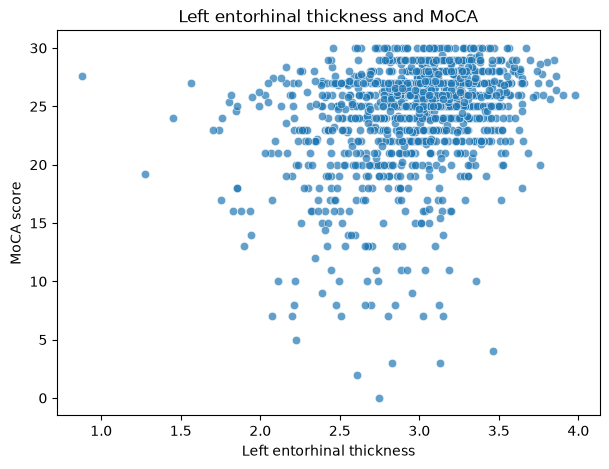

In [52]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=MOCATOTS_valid, x='LH_ENTORHINAL_AVGTH', y='MOCATOTS', alpha = 0.7)
plt.title('Left entorhinal thickness and MoCA')
plt.xlabel('Left entorhinal thickness')
plt.ylabel('MoCA score')
plt.show()

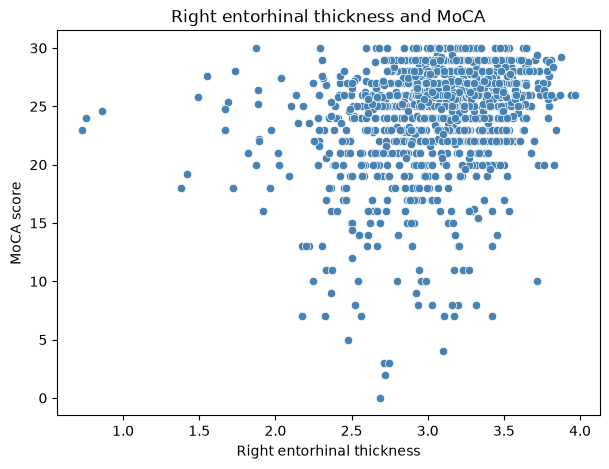

In [43]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=MOCATOTS_valid, x='RH_ENTORHINAL_AVGTH', y='MOCATOTS', color='steelblue')
plt.title('Right entorhinal thickness and MoCA')
plt.xlabel('Right entorhinal thickness')
plt.ylabel('MoCA score')
plt.show()

In [44]:
MOCATOTS_valid[joint_vars].corr(method='spearman')

,CDRSUM,CDRGLOB,MOCATOTS,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_AVGTH
CDRSUM,1.000000,0.945467,-0.569710,-0.291154,-0.266101
CDRGLOB,0.945467,1.000000,-0.543740,-0.279152,-0.253740
MOCATOTS,-0.569710,-0.543740,1.000000,0.285473,0.256869
LH_ENTORHINAL_AVGTH,-0.291154,-0.279152,0.285473,1.000000,0.645080
RH_ENTORHINAL_AVGTH,-0.266101,-0.253740,0.256869,0.645080,1.000000


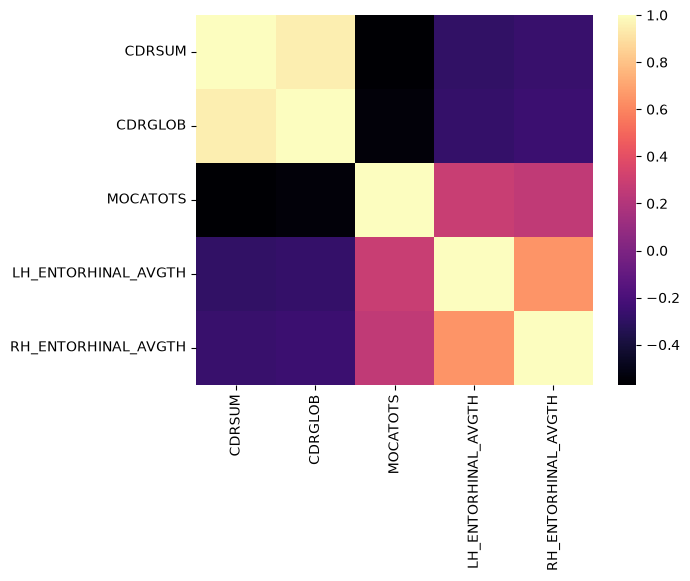

In [56]:
sns.heatmap(MOCATOTS_valid[joint_vars].corr(method='spearman') , cmap = 'magma')
plt.show()

In [63]:
APOE_Data = Data[Data['NACCAPOE'].isin([1, 2, 3, 4, 5, 6])]
APOE_Data.groupby('NACCAPOE')['CDRSUM'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
NACCAPOE,,,,
1.0,493,0.521298,0.0,1.292589
2.0,290,1.036207,0.0,1.937492
3.0,83,0.349398,0.0,0.743816
4.0,73,1.595890,0.5,2.119122
5.0,17,0.911765,0.0,2.906003
6.0,3,0.000000,0.0,0.000000


In [64]:
APOE_MoCA = APOE_Data[APOE_Data['MOCATOTS'].between(0, 30)]

APOE_MoCA.groupby('NACCAPOE')['MOCATOTS'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
NACCAPOE,,,,
1.0,490,25.102857,26.0,4.022477
2.0,289,24.021453,25.2,4.633598
3.0,83,25.771084,26.0,2.823099
4.0,73,22.747945,24.0,4.761539
5.0,17,25.776471,26.0,2.426811
6.0,3,26.400000,26.4,0.400000


In [65]:
APOE_Data.groupby('NACCAPOE')[['LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH']].agg(['count', 'mean', 'median', 'std'])

LH_ENTORHINAL_AVGTH                            RH_ENTORHINAL_AVGTH  \
                       count      mean median       std               count   
NACCAPOE                                                                      
1.0                      493  2.989061  3.030  0.370634                 493   
2.0                      290  2.933400  3.000  0.429884                 290   
3.0                       83  3.016386  3.050  0.313027                  83   
4.0                       73  2.819370  2.976  0.444286                  73   
5.0                       17  3.081824  3.082  0.336995                  17   
6.0                        3  3.091333  2.993  0.236373                   3   

                                      
              mean  median       std  
NACCAPOE                              
1.0       3.079665  3.1080  0.381553  
2.0       3.009452  3.0765  0.466862  
3.0       3.073855  3.0940  0.367332  
4.0       2.940836  2.9580  0.448029  
5.0       3.252824  3.2780  0.315981  
6.0       3.314000  3.3650  0.209215

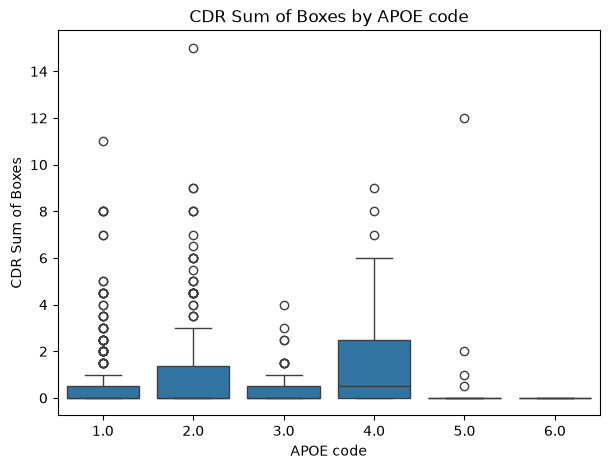

In [66]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=APOE_Data, x='NACCAPOE', y='CDRSUM')
plt.title('CDR Sum of Boxes by APOE code')
plt.xlabel('APOE code')
plt.ylabel('CDR Sum of Boxes')
plt.show()

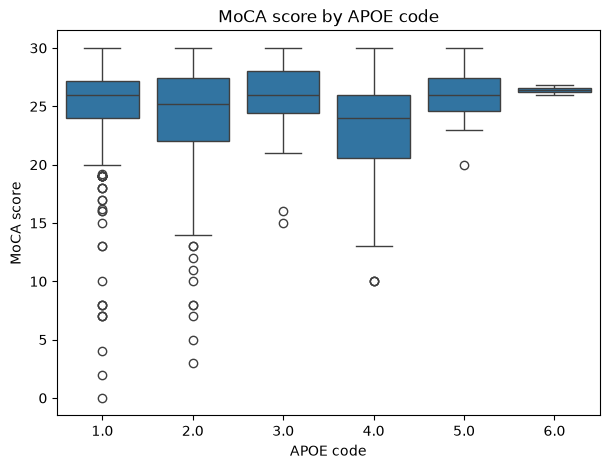

In [67]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=APOE_MoCA, x='NACCAPOE', y='MOCATOTS')
plt.title('MoCA score by APOE code')
plt.xlabel('APOE code')
plt.ylabel('MoCA score')
plt.show()